# 01 Clean: Online Retail II transactions

**Project:** customer segmentation for an online retailer, so marketing can stop sending everyone the same email.
**This notebook:** loads two years of transactions and documents the columns (Step 2), then cleans them into a table of real purchases with revenue (Step 3).

**Data:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), UCI Machine Learning Repository, id 502 (CC BY 4.0). All transactions of a UK-based online gift and homeware retailer between 1 December 2009 and 9 December 2011. Chen, D. (2019).

## 1. Load the data

The file is an Excel workbook with one sheet per year. If it is missing, it is downloaded once from UCI. Reading 1 million Excel rows takes about a minute.

In [1]:
from pathlib import Path
import io, urllib.request, zipfile
import pandas as pd
import numpy as np

RAW = Path("../data/raw/online_retail_II.xlsx")
URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"

if not RAW.exists():
    with urllib.request.urlopen(URL) as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extract("online_retail_II.xlsx", RAW.parent)

sheets = pd.read_excel(RAW, sheet_name=None)
for name, sheet in sheets.items():
    print(f"{name}: {len(sheet):,} rows")
tx = pd.concat(sheets.values(), ignore_index=True)
tx.head()

Year 2009-2010: 525,461 rows
Year 2010-2011: 541,910 rows


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [2]:
tx.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [3]:
tx.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Quantity,1067371.0,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445


## 2. Checking what the columns mean

In [4]:
inv = tx.Invoice.astype(str)
print("Invoice prefixes:", inv.str[0].value_counts().to_dict())
print(f"Date range: {tx.InvoiceDate.min()} to {tx.InvoiceDate.max()}")
print(f"Customers: {tx['Customer ID'].nunique():,}   Products: {tx.StockCode.nunique():,}   Countries: {tx.Country.nunique()}")
print(f"Rows with no Customer ID: {tx['Customer ID'].isna().sum():,} ({tx['Customer ID'].isna().mean():.1%})")

Invoice prefixes: {'5': 939382, '4': 108489, 'C': 19494, 'A': 6}
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Customers: 5,942   Products: 5,305   Countries: 43
Rows with no Customer ID: 243,007 (22.8%)


In [5]:
codes = tx.StockCode.astype(str)
non_product = codes[~codes.str.match(r"^\d{5}")]
non_product.value_counts().head(12)

StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
Name: count, dtype: int64

In [6]:
tx[codes.isin(["POST", "M", "BANK CHARGES", "AMAZONFEE", "ADJUST"])][["StockCode", "Description", "Quantity", "Price"]].drop_duplicates("StockCode")

,StockCode,Description,Quantity,Price
89,POST,POSTAGE,3,18.00
2697,M,Manual,1,4.00
18410,BANK CHARGES,Bank Charges,-1,15.00
70975,ADJUST,Adjustment by john on 26/01/2010 16,1,96.46
440688,AMAZONFEE,AMAZON FEE,-1,6706.71


What this tells me for the data dictionary:

- **Invoice** numbers starting with **C** are cancellations (they carry negative quantities). A handful start with **A**: accounting adjustments for bad debt.
- **StockCode** is normally a 5-digit product code, sometimes with a letter for a variant (`85123A`). Codes like `POST` (postage), `M` (manual entry), `BANK CHARGES`, `AMAZONFEE` and `ADJUST` are not products. They need to go before measuring what customers buy.
- **Price** is the unit price in pounds sterling; **Quantity** is units on the invoice line.
- **Customer ID** is missing for almost a quarter of the rows. Without it a purchase cannot be linked to a customer, so those rows cannot be segmented.
- Most customers are in the United Kingdom, with smaller numbers across Europe and elsewhere. Many buy in bulk: the business sells to individuals and to small shops.

---
# Step 3: Clean the transactions

In [7]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

Each cleaning rule is applied in turn and the rows it removes are counted, so every decision is visible.

In [8]:
log = []
def step(frame, label):
    log.append({"rule": label, "rows left": len(frame)})
    return frame

df = step(tx, "Raw data")
df = step(df.drop_duplicates(), "Remove exact duplicate lines")
df = step(df.dropna(subset=["Customer ID"]), "Remove lines with no Customer ID")
cancel = df.Invoice.astype(str).str.startswith("C")
cancelled_value = (df.loc[cancel, "Quantity"] * df.loc[cancel, "Price"]).sum()
df = step(df[~cancel], "Remove cancellations (invoice starts with C)")
df = step(df[~df.Invoice.astype(str).str.startswith("A")], "Remove bad-debt adjustments (none left: no Customer ID)")
df = step(df[df.StockCode.astype(str).str.match(r"^\d{5}")], "Keep real products only (drop postage, fees, manual lines)")
df = step(df[(df.Quantity > 0) & (df.Price > 0)], "Keep positive quantity and price")

steps_table = pd.DataFrame(log)
steps_table["removed"] = -steps_table["rows left"].diff().fillna(0).astype(int)
print(f"Value of cancelled lines removed: £{abs(cancelled_value):,.0f}")
steps_table

Value of cancelled lines removed: £1,084,813


,rule,rows left,removed
0,Raw data,1067371,0
1,Remove exact duplicate lines,1033036,34335
2,Remove lines with no Customer ID,797885,235151
3,Remove cancellations (invoice starts with C),779495,18390
4,Remove bad-debt adjustments (none left: no Cus...,779495,0
5,"Keep real products only (drop postage, fees, m...",776637,2858
6,Keep positive quantity and price,776577,60


Why these rules:

- **Duplicates:** identical lines (same invoice, product, quantity, time) are almost certainly double-recorded and would inflate spend.
- **Missing Customer ID:** these purchases cannot be attributed to anyone. They are real revenue, but segmentation is about customers. (A real project would ask why almost a quarter of sales lines are anonymous, for example guest checkout.)
- **Cancellations:** I remove them rather than subtract them. Many cancellations refer to orders placed before the data starts, so subtracting would leave some customers with negative spend.
- **Non-product lines:** postage and fees are not buying behaviour.

## 3. Revenue per line

In [9]:
df = df.assign(customer_id=df["Customer ID"].astype(int), revenue=df.Quantity * df.Price)
df = df.rename(columns={"Invoice": "invoice", "StockCode": "stock_code", "Description": "description",
                        "Quantity": "quantity", "InvoiceDate": "invoice_date", "Price": "price", "Country": "country"})
df = df[["invoice", "invoice_date", "customer_id", "country", "stock_code", "description", "quantity", "price", "revenue"]]
df = df.astype({"invoice": str, "stock_code": str, "description": str})  # mixed numbers and text in Excel
print(f"{len(df):,} purchase lines, {df.customer_id.nunique():,} customers, {df.invoice.nunique():,} invoices")
print(f"Total revenue: £{df.revenue.sum():,.0f}")

776,577 purchase lines, 5,852 customers, 36,594 invoices
Total revenue: £17,068,568


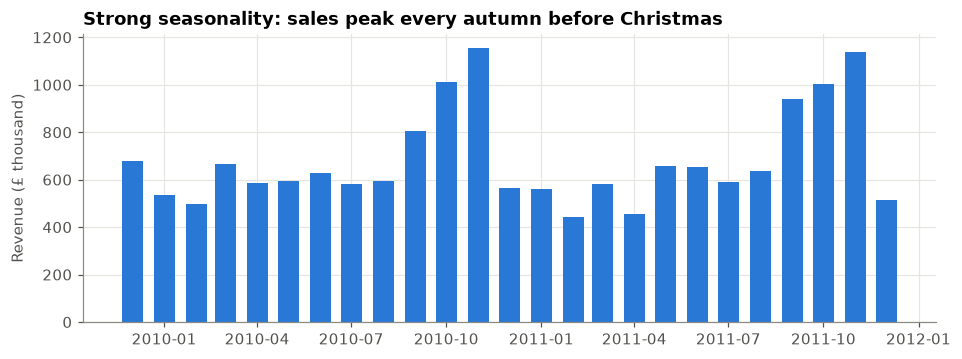

In [10]:
monthly = df.set_index("invoice_date").revenue.resample("MS").sum() / 1000
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(monthly.index, monthly.values, width=20, color=BLUE)
ax.set_ylabel("Revenue (£ thousand)")
ax.set_title("Strong seasonality: sales peak every autumn before Christmas")
fig.savefig("../figures/monthly_revenue.png")
plt.show()

December 2011 looks low only because the data stops on 9 December.

In [11]:
per_customer = df.groupby("customer_id").revenue.sum().sort_values(ascending=False)
top10 = per_customer.head(len(per_customer) // 10).sum() / per_customer.sum()
print(f"The top 10% of customers bring in {top10:.0%} of revenue.")
print(f"UK share of customers: {(df.groupby('customer_id').country.first() == 'United Kingdom').mean():.0%}")

The top 10% of customers bring in 64% of revenue.
UK share of customers: 91%


In [12]:
df.to_parquet("../data/processed/transactions_clean.parquet")

## 4. What the cleaning showed

1. Almost a quarter of transaction lines have no customer attached, and they cannot be segmented.
2. Sales are strongly seasonal, peaking in October and November. Any campaign calendar should respect that.
3. Revenue is very concentrated: the top 10% of customers bring in almost two thirds of revenue. Treating every customer the same is clearly wasteful.